In [ ]:
# --- project bootstrap ---
# common/ holds the shared modules (geom_utils, mosaic_utils*).
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import numpy as np
import gc
import lsst.daf.butler as DafButler
import lsst.summit.utils.plotting as splot
from lsst.summit.utils.utils import getCameraFromInstrumentName

from lsst.pipe.tasks.visualizeVisit import (
    VisualizeBinExpConfig,
    VisualizeBinExpTask,
    VisualizeMosaicExpConfig,
    VisualizeMosaicExpTask,
)

import lsst.afw.display as afwDisplay
from matplotlib.colors import LogNorm
from mosaic_utils import get_stacked_image 




In [6]:
#Collections=['LSSTComCam/runs/nightlyValidation']
butler = DafButler.Butler('embargo', collections=["LSSTCam/runs/DRP/FL/w_2025_19/DM-50795","u/ataranto/lsst_outputs"], instrument='LSSTCam')
registry = butler.registry
day_obs = 20250506
seq=696
visit=day_obs*100000+seq
#visit=2025042200250


info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
ra_so = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
dec_so = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()


In [4]:
Dref = list(registry.queryDatasets('post_isr_image', where=f"visit={visit} and detector=94"))
camera = getCameraFromInstrumentName("LSSTCam")
plt.close('all')
exposures = [ butler.get(dr) for dr in Dref]
print(len(exposures))
img=exposures[0].image.array


0


IndexError: list index out of range

In [ ]:


#dataImgs = [butler.get(dr) for dr in Dref ]#if camera[dr.dataId["detector"]].getName() == 'R22_S11']
plt.close('all')

print(Dref)

# plot with the utils
#_ = splot.plot(dataImgs[0], stretch='ccs',title=f'{visit}')
def bin_image(image, camera, binning=8):
    visualizeBinExpConfig = VisualizeBinExpConfig()
    visualizeBinExpConfig.binning = binning
    visualizeBinExpTask = VisualizeBinExpTask(config=visualizeBinExpConfig)
    return visualizeBinExpTask.run(inputExp=image, camera=camera).outputExp

binning = 8
exposures_binned = [bin_image(exposure, camera, binning) for exposure in exposures]
visualizeMosaicExpConfig = VisualizeMosaicExpConfig()
visualizeMosaicExpConfig.binning = binning
visualizeMosaicExpTask = VisualizeMosaicExpTask(config=visualizeMosaicExpConfig)
mosaic = visualizeMosaicExpTask.run(inputExps=exposures_binned, camera=camera).outputData
backend='matplotlib'
visit_cmap = "gray"
scale = "linear"
print(type(mosaic.array))


fig = plt.figure(figsize=(16,16))
disp = afwDisplay.Display(1, backend, cmap=visit_cmap)
norm=LogNorm(vmin=1400,vmax=2500)
plt.imshow(mosaic.array,origin='lower',norm=norm)#disp = afwDisplay.Display(1, backend, cmap=visit_cmap)

#disp.scale(scale, min='zscale')


#disp.setImageColormap(visit_cmap)
#disp.mtv(mosaic)


NameError: name 'plt' is not defined

: 

In [ ]:
plt.close('all')
dataImgs=exposures

In [ ]:
wcs = dataImgs[0].wcs #.getFitsMetadata().items()
ra_so, dec_so=wcs.getSkyOrigin()
ra_so=(float(ra_so)* u.rad).to(u.deg).value
dec_so=(float(dec_so)* u.rad).to(u.deg).value
print(ra_so,dec_so)
#detIdMap = camera.getIdMap()
#detNameMap = {key: det.getName() for key, det in detIdMap.items()}
#detNameMap

225.00094394859988 -40.000047881641066


In [ ]:
image=dataImgs[0]
header = {key: val for key, val in image.getMetadata().items()}
ra,dec=header['RA'], header['DEC']
print(header['ROTPA'])


309.418960393311


In [9]:
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u

filters = {"Vmag": "<5"}

# Includi la colonna Vmag e applica il filtro a monte
vizier = Vizier(columns=["*", "Vmag"], column_filters=filters)
vizier.ROW_LIMIT = -1
center = SkyCoord(ra=ra_so*u.deg, dec=dec_so*u.deg, frame='icrs')
dist = 25* u.deg  

# Query sul catalogo Hipparcos piu leggero tanto mi interessano solo le stelle piu brillanti che ci sono anche qua
result = vizier.query_region(center, radius=dist, catalog="I/239/hip_main")

try:
    stars = result[0][['HIP','Vmag', '_RA.icrs', '_DE.icrs']]
    stars_coords = SkyCoord(ra=stars['_RA.icrs'], dec=stars['_DE.icrs'], frame='icrs')
    radial_distances = stars_coords.separation(center)

    # Add the radial distances as a new column to the table
    stars['Radial_Distance'] = radial_distances
#    stars=stars[stars['Radial_Distance']>1.0]
    stars.sort('Vmag')
    print(stars)
    stars=stars[:5]

except:
    print("Nessuna stella trovata con Vmag > 4 in questa zona.")
    stars=[]



 HIP   Vmag   _RA.icrs     _DE.icrs    Radial_Distance  
       mag      deg          deg             deg        
----- ----- ------------ ------------ ------------------
80763  1.06 247.35192046 -26.43200249 21.115594866059567
78401  2.29 240.08335942 -22.62170993 16.742009941525264
84012  2.43 257.59453052 -15.72491023  18.23440365332536
81377  2.54 249.28974079 -10.56708997   8.64797274420488
78820  2.56 241.35929462 -19.80545336 13.844649464826803
74785  2.61 229.25172845  -9.38291740 12.974986872439008
77070  2.63 236.06697851   6.42562699 13.688700545451232
79593  2.73 243.58641439  -3.69432297 2.8376098445454834
72622  2.75 222.71963807 -16.04177818 21.312874456116674
  ...   ...          ...          ...                ...
78821  4.90 241.36064081 -19.80186007 13.841010495216928
81724  4.91 250.39326259 -17.74216686   14.4091082363087
73473  4.91 225.24311921  -8.51894314  16.70277048275478
75379  4.92 231.04953961 -10.32226578 11.573025955893518
72631  4.93 222.75446368  -2.29

In [12]:
from skyfield.api import load, Loader, Topos
from astropy.time import Time
from astropy.coordinates import SkyCoord

# Input time in MJD
time_astropy = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()

# mjd = header['MJD']
# time_astropy = Time(mjd, format='mjd')
ts = load.timescale()
time = ts.tdb(jd=time_astropy.jd)

# Load ephemeris
eph = Loader('../data/ephemeris', verbose=False)('de440s.bsp')  # or 'de440s.bsp' for more precision

# Observer (optional: for topocentric correction)
earth = eph['earth']
moon = eph['moon']

# Get position of the Moon from Earth's center (geocentric)
moon_position = earth.at(time).observe(moon).apparent()
ra_moon, dec_moon, distance = moon_position.radec()

ra_deg = ra_moon.hours * 15  # Convert hours to degrees
dec_deg = dec_moon.degrees  # Already in degrees

#print("RA (deg):", ra_deg)
#print("Dec (deg):", dec_deg)

# Moon's position as SkyCoord
moon_coord = SkyCoord(ra=ra_deg * u.deg, dec=dec_deg * u.deg, frame='icrs')

#print(moon_coord) #.to_string("hmsdms", sep=":"))

# Center FoV position as SkyCoord

# Compute angular separation
rot=moon_coord.position_angle(center).deg
moon_to_center_distance = moon_coord.separation(center)
print('rot angle',moon_coord.position_angle(center).deg)
print("Moon to Center FoV Distance (deg):", moon_to_center_distance.deg)

rot angle 97.89942906838931
Moon to Center FoV Distance (deg): 74.42037203995864


from astropy.coordinates import get_body, EarthLocation, solar_system_ephemeris, AltAz

def convert_radec_to_altaz(loc, t, radecCoord):
    if not isinstance(t, Time):
        t = Time(t)
    loc = EarthLocation.of_site(loc)
    altaz = AltAz(location=loc, obstime=t)
    radecCoord = SkyCoord(radecCoord)
    return radecCoord.transform_to(altaz)

a=convert_radec_to_altaz('rubin',time_astropy,moon_coord)
print(a)
print(mjd)

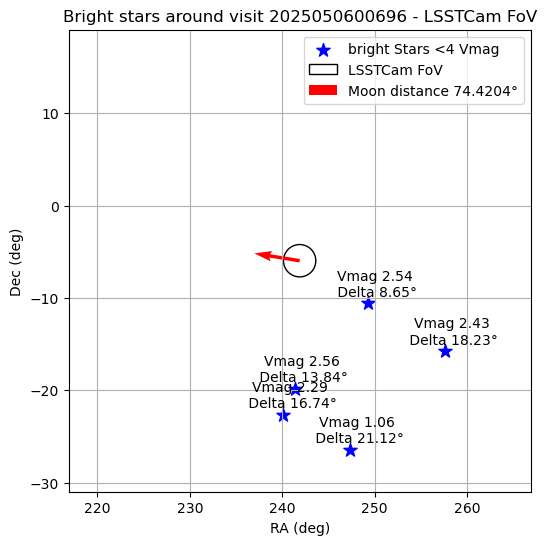

In [17]:
from matplotlib.patches import Rectangle

# Calculate the range of RA and Dec
#ra_min, ra_max = stars['_RA.icrs'].min(), stars['_RA.icrs'].max()
#dec_min, dec_max = stars['_DE.icrs'].min(), stars['_DE.icrs'].max()

# Expand the range by 15%
#ra_range = ra_max - ra_min
#dec_range = dec_max - dec_min
#ra_min -= 0.12 * ra_range
#ra_max += 0.12 * ra_range
#dec_min -= 0.12 * dec_range
#dec_max += 0.12 * dec_range

# Update the plot
import matplotlib.transforms as transforms

# Define the side length and rotation angle (in degrees)
side_length = 2.5
rotation_angle = 55 #header['ROTPA']  # Set your desired rotation angle here



circle = plt.Circle((ra_so, dec_so), 1.75, color='black', fill=False, label='LSSTCam FoV')
# Create the rectangle centered at (ra_so, dec_so)
rect = Rectangle(
    (ra_so - side_length/2, dec_so - side_length/2),
    side_length, side_length,
    angle=0,  # No rotation here; we'll apply it with the transform
    color='green', fill=False, label=f'Detector rot'
)
# Rotate around the center (ra_so, dec_so)
# Apply rotation around the center (ra_so, dec_so) and keep proportions fixed (no aspect distortion)
plt.figure(figsize=(10, 6))

ax = plt.gca()
t = transforms.Affine2D().rotate_deg_around(ra_so, dec_so, rotation_angle) + ax.transData
rect.set_transform(t)
# plt.gca().add_artist(TEA)

plt.scatter(stars['_RA.icrs'], stars['_DE.icrs'], c='blue', label='bright Stars <4 Vmag', s=100,marker='*')
plt.gca().add_artist(circle)
plt.quiver(ra_so, dec_so, ra_deg - ra_so, dec_deg - dec_so, angles='xy', scale_units='xy',scale=15, color='r', label='Moon distance '+f"{moon_to_center_distance.deg:.4f}°")
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.gca().set_aspect('equal')

# Set the new limits
plt.xlim(ra_so-25, ra_so+25)
plt.ylim(dec_so-25, dec_so+25)

for i, txt in enumerate(stars['Vmag']):
    separation = stars['Radial_Distance'][i]  # Convert to degrees
    plt.annotate(f"Vmag {txt:.2f}\n Delta {separation:.2f}°", 
                 (stars['_RA.icrs'][i], stars['_DE.icrs'][i]), 
                 textcoords="offset points", xytext=(5, 5), ha='center')
plt.title(f"Bright stars around visit {visit} - LSSTCam FoV")
plt.grid(True)
plt.legend()

plt.show()


In [ ]:
from astropy.time import Time
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
import astropy.units as u
from datetime import datetime
import numpy as np
def calculate_rotation_angle(ra_deg, dec_deg):

    location = EarthLocation.of_site('rubin')
    # Current time
    current_time= butler.get("raw.visitInfo", exposure=2025042200240, detector=94).date.toAstropy()





    # Calculate Local Sidereal Time (LST)
    lst = current_time.sidereal_time('apparent', longitude=location.lon)
    lst_deg = lst.deg

    # Hour Angle (HA)
    ha = (lst_deg - ra_deg) % 360

    # Convert HA and DEC to radians
    ha_rad = np.radians(ha)
    dec_rad = np.radians(dec_deg)
    lat_rad = np.radians(location.lat)

    # Calculate the angle between the RA-DEC and ALT-AZ grids
    angle = np.arccos(np.sin(lat_rad) * np.sin(dec_rad) + np.cos(lat_rad) * np.cos(dec_rad) * np.cos(ha_rad))
    angle_deg = np.degrees(angle)

    return angle_deg

# Example usage

angle = calculate_rotation_angle(ra_so, dec_so)
print(angle)
for st in stars:
    star_coord=SkyCoord(ra=st['_RA.icrs'] * u.deg, dec=st['_DE.icrs'] * u.deg, frame='icrs')
    star_rot=star_coord.position_angle(center).deg
    star_sep = star_coord.separation(center).deg
    print('rot ',star_rot+angle.value,'  sep ',star_sep)

21.763625564602773 deg
rot  88.7474552444192   sep  5.094159002586553
rot  26.90605727502318   sep  3.145967904764512
rot  298.8035664247346   sep  6.769449892312504
rot  26.14919216415077   sep  2.1101281786204766
rot  299.06093059222087   sep  4.1232543310068035
rot  338.0390585799153   sep  6.285657348863979
rot  249.0171788380349   sep  5.686486588177884
rot  373.8275406117632   sep  7.1115942356561765
rot  145.31516135729072   sep  4.145789122379459
rot  130.2451067226872   sep  7.95148162693053
rot  169.1320058523947   sep  5.810516267847505
rot  363.8925553890059   sep  5.523811792066526
rot  46.03065250751585   sep  3.9002070276871295
rot  308.3333840550585   sep  7.589938936752758
rot  118.64514430218443   sep  7.118270979341162
rot  255.27289505567614   sep  5.514223039548046
rot  275.2663613552693   sep  5.05614501341041
rot  352.8715529935273   sep  5.086566852753973
rot  171.15020393891785   sep  5.652593240448733


In [ ]:



for st in stars:
    star_coord=SkyCoord(ra=st['_RA.icrs'] * u.deg, dec=st['_DE.icrs'] * u.deg, frame='icrs')
    star_rot=star_coord.position_angle(center).deg
    star_sep = star_coord.separation(center).deg
    print(star_rot,star_sep)



263.15449641702253 6.383627415426776
156.79186602707625 7.008387464621526
159.15713553270805 3.5659704670172587
97.45871620123134 3.2755989676724218


In [ ]:
# Python script to calculate the parallactic angle of Spica from the Vera Rubin Observatory
import math
from astropy.time import Time
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
from astropy import units as u

def radians(degrees):
    return math.radians(degrees)

def degrees(radians):
    return math.degrees(radians)

# Convert HMS (hours, minutes, seconds) to decimal degrees
def hms_to_degrees(hours, minutes, seconds):
    return 15 * (hours + minutes / 60 + seconds / 3600)

# Convert DMS (degrees, minutes, seconds) to decimal degrees
def dms_to_degrees(degrees, minutes, seconds):
    sign = -1 if degrees < 0 else 1
    return sign * (abs(degrees) + minutes / 60 + seconds / 3600)

def calculate_parallactic_angle(ra, dec, latitude, lst):
    ra_rad = radians(ra)
    dec_rad = radians(dec)
    lat_rad = radians(latitude)
    lst_rad = radians(lst)

    # Calculate hour angle (H)
    H = lst_rad - ra_rad
    H = (H + math.pi) % (2 * math.pi) - math.pi

    numerator = math.sin(H)
    denominator = math.tan(lat_rad) * math.cos(dec_rad) - math.sin(dec_rad) * math.cos(H)

    if denominator == 0:
        return float('nan')

    psi = math.atan2(numerator, denominator)
    psi_deg = degrees(psi)
    return psi_deg

# Coordinates of Spica (RA: 13h 25m 11.6s, Dec: -11° 09' 41")
ra = hms_to_degrees(14, 39, 41.70)
dec = dms_to_degrees(-60, 50,16)

# Vera Rubin Observatory location
latitude = -30.2407  # degrees
longitude = -70.7366  # degrees

# Observation time (UTC) and LST calculation
time = Time("2025-05-14T05:30:00", scale="utc")
location = EarthLocation.of_site('rubin')
lst = time.sidereal_time('mean', longitude).degree

# Sky coordinates of Spica
spica = SkyCoord(ra=ra * u.deg, dec=dec * u.deg, frame='icrs')
altaz = AltAz(obstime=time, location=location)
spica_altaz = spica.transform_to(altaz)

# Calculate parallactic angle
parallactic_angle = calculate_parallactic_angle(ra, dec, latitude, lst)
print(f"Parallactic Angle of Spica from Vera Rubin Observatory at 4:30 AM UTC on 14 May 2025: {parallactic_angle:.2f} degrees")
print(f"Altitude: {spica_altaz.alt:.2f}, Azimuth: {spica_altaz.az:.2f}")


Parallactic Angle of Spica from Vera Rubin Observatory at 4:30 AM UTC on 14 May 2025: 38.45 degrees
Altitude: 55.58 deg, Azimuth: 200.07 deg
